   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 80.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 52.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 15.2 MB/s eta 0:00:00


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Training CartPole Agent...
The agent learns to keep the pole balanced.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CartPole training completed.
Average reward: 360.8

Training LunarLander Agent...
The agent learns to land the spacecraft safely.


<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type swigvarlink has no __module__ attribute


LunarLander training completed.
Average reward: -934.28

Reinforcement Learning Training Results


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Environment,Algorithm,Training Steps,Average Reward,Reward Std.
0,CartPole,PPO,10000,360.80,126.37
1,LunarLander,PPO,50000,-934.28,299.34


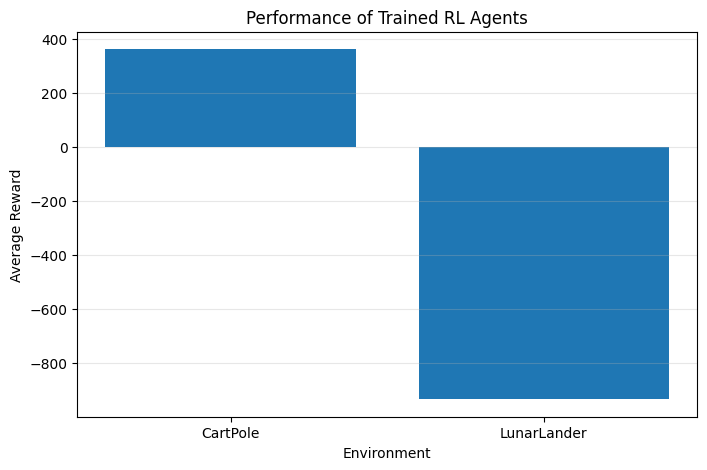

/usr/local/lib/python3.13/dist-packages/gymnasium/wrappers/rendering.py:292: UserWarning: WARN: Overwriting existing videos at /content/cartpole_video folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Recording CartPole demonstration...


/usr/local/lib/python3.13/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CartPole demonstration:


Recording LunarLander demonstration...


/usr/local/lib/python3.13/dist-packages/gymnasium/wrappers/rendering.py:292: UserWarning: WARN: Overwriting existing videos at /content/lunarlander_video folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


LunarLander demonstration:


In [1]:
# Install required libraries
!pip install -q "stable-baselines3[extra]" "gymnasium[box2d]"

# Import required libraries
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy
from IPython.display import display, Video
from pathlib import Path

# 1. Train and Evaluate CartPole Agent
print("Training CartPole Agent...")
print("The agent learns to keep the pole balanced.")

cartpole_env = gym.make("CartPole-v1")

# Create PPO agent
cartpole_model = PPO(
    "MlpPolicy",
    cartpole_env,
    verbose=0
)

# Train the agent
cartpole_model.learn(total_timesteps=10000)

# Evaluate the trained agent
cartpole_mean_reward, cartpole_std_reward = evaluate_policy(
    cartpole_model,
    cartpole_env,
    n_eval_episodes=10
)

cartpole_env.close()

print("CartPole training completed.")
print("Average reward:", round(cartpole_mean_reward, 2))

# 2. Train and Evaluate LunarLander Agent
print("\nTraining LunarLander Agent...")
print("The agent learns to land the spacecraft safely.")

lander_env = gym.make("LunarLander-v3")

# Create PPO agent
lander_model = PPO(
    "MlpPolicy",
    lander_env,
    verbose=0
)

# Train the agent
lander_model.learn(total_timesteps=50000)

# Evaluate the trained agent
lander_mean_reward, lander_std_reward = evaluate_policy(
    lander_model,
    lander_env,
    n_eval_episodes=10
)

lander_env.close()

print("LunarLander training completed.")
print("Average reward:", round(lander_mean_reward, 2))

# 3. Create Summary Table
results = pd.DataFrame({
    "Environment": ["CartPole", "LunarLander"],
    "Algorithm": ["PPO", "PPO"],
    "Training Steps": [10000, 50000],
    "Average Reward": [
        round(cartpole_mean_reward, 2),
        round(lander_mean_reward, 2)
    ],
    "Reward Std.": [
        round(cartpole_std_reward, 2),
        round(lander_std_reward, 2)
    ]
})

print("\nReinforcement Learning Training Results")
display(results)

# 4. Plot Average Reward
plt.figure(figsize=(8, 5))

plt.bar(
    results["Environment"],
    results["Average Reward"]
)

plt.title("Performance of Trained RL Agents")
plt.xlabel("Environment")
plt.ylabel("Average Reward")
plt.grid(axis="y", alpha=0.3)

plt.show()

# 5. Record CartPole Demonstration
print("Recording CartPole demonstration...")

record_dir = Path("cartpole_video")
record_dir.mkdir(exist_ok=True)

video_env = gym.make(
    "CartPole-v1",
    render_mode="rgb_array"
)

video_env = gym.wrappers.RecordVideo(
    video_env,
    video_folder=str(record_dir),
    episode_trigger=lambda episode_id: episode_id == 0
)

observation, info = video_env.reset()

for step in range(500):

    # Trained model selects an action
    action, _ = cartpole_model.predict(
        observation,
        deterministic=True
    )

    observation, reward, terminated, truncated, info = video_env.step(action)
    if terminated or truncated:
        break

video_env.close()
cartpole_videos = list(record_dir.glob("*.mp4"))

if cartpole_videos:
    print("CartPole demonstration:")
    display(Video(str(cartpole_videos[0]), embed=True))

# 6. Record LunarLander Demonstration
print("Recording LunarLander demonstration...")
record_dir = Path("lunarlander_video")
record_dir.mkdir(exist_ok=True)

video_env = gym.make(
    "LunarLander-v3",
    render_mode="rgb_array"
)

video_env = gym.wrappers.RecordVideo(
    video_env,
    video_folder=str(record_dir),
    episode_trigger=lambda episode_id: episode_id == 0
)

observation, info = video_env.reset()
for step in range(1000):

    # Trained model selects an action
    action, _ = lander_model.predict(
        observation,
        deterministic=True)

    observation, reward, terminated, truncated, info = video_env.step(action)

    if terminated or truncated:
        break

video_env.close()
lander_videos = list(record_dir.glob("*.mp4"))

if lander_videos:
    print("LunarLander demonstration:")
    display(Video(str(lander_videos[0]), embed=True))